# End-to-End Exploratory Data Analysis

## Online Retail Dataset

This project presents a complete and reproducible Exploratory
Data Analysis of the UCI Online Retail dataset.

### Project Objectives

- Understand the dataset and its business context.
- Assess data quality and investigate unusual observations.
- Explore numerical, categorical, and temporal variables.
- Investigate distributions and relationships.
- Identify meaningful business patterns.
- Communicate findings, limitations, and uncertainty.

### Observational Unit

Each row represents an invoice line item, not necessarily
an entire invoice or a unique customer.

### Data Source

UCI Machine Learning Repository — Online Retail

https://archive.ics.uci.edu/dataset/352/online+retail

## 1. Project Setup

Import the required libraries, locate the project directory,
define project paths, and prepare the output directories.

The notebook uses the project's local Python environment
managed by uv.

In [14]:
from pathlib import Path

import numpy as np
import pandas as pd
import seaborn as sns

from scipy import stats
from IPython.display import display
from matplotlib.figure import Figure
from matplotlib_inline.backend_inline import set_matplotlib_formats

set_matplotlib_formats("png")


# --------------------------------------------------
# 1. Locate the project root
# --------------------------------------------------

def find_project_root(start: Path) -> Path:
    """
    Find the project root by locating pyproject.toml.
    """

    for candidate in (start, *start.parents):
        if (candidate / "pyproject.toml").is_file():
            return candidate

    raise FileNotFoundError(
        "Could not locate the project root containing pyproject.toml."
    )


PROJECT_ROOT = find_project_root(Path.cwd())


# --------------------------------------------------
# 2. Define project paths
# --------------------------------------------------

DATA_DIR = PROJECT_ROOT / "data"

RAW_DATA_DIR = DATA_DIR / "raw"
INTERIM_DATA_DIR = DATA_DIR / "interim"
PROCESSED_DATA_DIR = DATA_DIR / "processed"

NOTEBOOK_DIR = PROJECT_ROOT / "notebooks"

OUTPUT_DIR = PROJECT_ROOT / "outputs"
TABLE_DIR = OUTPUT_DIR / "tables"
PROFILING_DIR = OUTPUT_DIR / "profiling"

REPORT_DIR = PROJECT_ROOT / "reports"
FIGURE_DIR = REPORT_DIR / "figures"

SOURCE_DIR = PROJECT_ROOT / "src"
CONFIG_DIR = PROJECT_ROOT / "config"
LOG_DIR = PROJECT_ROOT / "logs"


# --------------------------------------------------
# 3. Define dataset information
# --------------------------------------------------

DATASET_NAME = "Online Retail"

RAW_DATA_PATH = RAW_DATA_DIR / "Online Retail.xlsx"

DATASET_SHA256 = (
    "43465a06f2ccf7c8b5bd2892bc7defb52f97487934fe93b16ae4c3936424676d"
)


# --------------------------------------------------
# 4. Create required output directories
# --------------------------------------------------

OUTPUT_DIRECTORIES = [
    INTERIM_DATA_DIR,
    PROCESSED_DATA_DIR,
    TABLE_DIR,
    PROFILING_DIR,
    FIGURE_DIR,
    LOG_DIR,
]

for directory in OUTPUT_DIRECTORIES:
    directory.mkdir(parents=True, exist_ok=True)


# --------------------------------------------------
# 5. Verify the project environment and raw data
# --------------------------------------------------

if not RAW_DATA_PATH.is_file():
    raise FileNotFoundError(
        f"Raw dataset not found: {RAW_DATA_PATH}"
    )


print("Project setup completed successfully.")
print("-" * 50)
print(f"Project root : {PROJECT_ROOT}")
print(f"Dataset      : {DATASET_NAME}")
print(f"Dataset path : {RAW_DATA_PATH}")
print(f"Dataset size : {RAW_DATA_PATH.stat().st_size:,} bytes")
print("-" * 50)

Project setup completed successfully.
--------------------------------------------------
Project root : d:\coding\eda\Part IX - Capstone
Dataset      : Online Retail
Dataset path : d:\coding\eda\Part IX - Capstone\data\raw\Online Retail.xlsx
Dataset size : 23,715,344 bytes
--------------------------------------------------


## 2. Visualization Convention

This project uses Matplotlib's object-oriented API exclusively.

Figures are created using matplotlib.figure.Figure, and Axes
are obtained through the Figure's subplots() method.

IPython's display() function is used to publish figures
immediately at the point of execution.

The pyplot API is not used anywhere in this project.

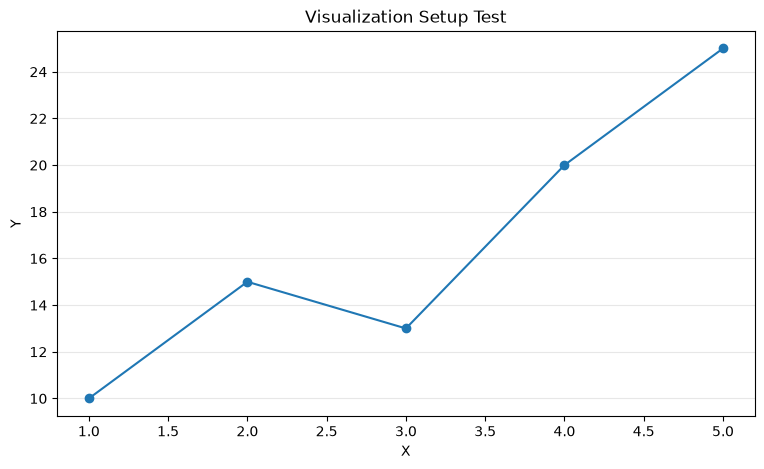

The next Python statement has executed.


In [15]:
fig = Figure(figsize=(9, 5))

ax = fig.subplots()

ax.plot(
    [1, 2, 3, 4, 5],
    [10, 15, 13, 20, 25],
    marker="o",
)

ax.set_title("Visualization Setup Test")
ax.set_xlabel("X")
ax.set_ylabel("Y")

ax.grid(axis="y", alpha=0.3)

# Render synchronously
fig.canvas.draw()

# Display immediately
display(fig)

print("The next Python statement has executed.")

## 3. Data Acquisition and Initial Inspection

Before conducting any analysis, we must establish that the
correct dataset has been acquired and loaded successfully.

This section covers:

1. Verifying the integrity of the original dataset.
2. Loading the Excel workbook into Pandas.
3. Inspecting its structure and dimensions.
4. Examining variable names and data types.
5. Reviewing initial observations.

The original dataset will remain unchanged. Any cleaning,
transformation, or derived data will be handled separately.

### 3.1 Data Integrity Verification

We use a SHA-256 checksum to verify that the local dataset
matches the file fingerprint recorded during acquisition.

This helps detect accidental modifications to the original
workbook.

In [16]:
import hashlib


def calculate_sha256(file_path: Path) -> str:
    """Calculate the SHA-256 checksum of a file."""

    sha256 = hashlib.sha256()

    with file_path.open("rb") as file:
        for chunk in iter(lambda: file.read(1024 * 1024), b""):
            sha256.update(chunk)

    return sha256.hexdigest()


actual_sha256 = calculate_sha256(RAW_DATA_PATH)

print("Expected SHA-256:", DATASET_SHA256)
print("Actual SHA-256:  ", actual_sha256)

if actual_sha256 != DATASET_SHA256:
    raise ValueError(
        "Dataset integrity verification failed. "
        "The original dataset may have been modified."
    )

print("\nDataset integrity verified successfully.")


Expected SHA-256: 43465a06f2ccf7c8b5bd2892bc7defb52f97487934fe93b16ae4c3936424676d
Actual SHA-256:   43465a06f2ccf7c8b5bd2892bc7defb52f97487934fe93b16ae4c3936424676d

Dataset integrity verified successfully.


### 3.2 Loading the Dataset

We will load the original Excel workbook using Pandas.

Identifier columns will initially be represented as strings.
Identifiers are labels, not numerical measurements, even when
their values contain digits.

We will not perform any cleaning at this stage.

In [17]:
df = pd.read_excel(
    RAW_DATA_PATH,
    sheet_name="Online Retail",
    engine="openpyxl",
    dtype={
        "InvoiceNo": "string",
        "StockCode": "string",
        "CustomerID": "string",
    },
)

print("Dataset loaded successfully.")
print(f"Shape: {df.shape[0]:,} rows × {df.shape[1]} columns")


Dataset loaded successfully.
Shape: 541,909 rows × 8 columns


### 3.3 Structural Inspection

We begin with a structural overview before examining individual
variables or calculating statistics.

The inspection includes:

- Dataset dimensions.
- Column names.
- Data types.
- Non-null counts.
- Memory usage.

In [18]:
print("Dataset shape:", df.shape)

print("\nColumn names:")
display(pd.Index(df.columns))

print("\nDataFrame information:")
df.info(memory_usage="deep")


Dataset shape: (541909, 8)

Column names:


Index(['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate',
       'UnitPrice', 'CustomerID', 'Country'],
      dtype='str')


DataFrame information:
<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  string        
 1   StockCode    541909 non-null  string        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  string        
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(1), int64(1), object(1), str(1), string(3)
memory usage: 168.2 MB


### 3.4 Initial Observations

We inspect a few records to understand how observations are
represented.

At this stage, we are looking for structural clues, not making
conclusions about the dataset.

In [19]:
print("First five observations:")
display(df.head())

print("Last five observations:")
display(df.tail())

print("Five randomly selected observations:")
display(df.sample(n=5, random_state=42))

First five observations:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom


Last five observations:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
541904,581587,22613,PACK OF 20 SPACEBOY NAPKINS,12,2011-12-09 12:50:00,0.85,12680,France
541905,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,2011-12-09 12:50:00,2.10,12680,France
541906,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,2011-12-09 12:50:00,4.15,12680,France
541907,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,2011-12-09 12:50:00,4.15,12680,France
541908,581587,22138,BAKING SET 9 PIECE RETROSPOT,3,2011-12-09 12:50:00,4.95,12680,France


Five randomly selected observations:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
209268,555200,71459,HANGING JAM JAR T-LIGHT HOLDER,24,2011-06-01 12:05:00,0.85,17315,United Kingdom
207108,554974,21128,GOLD FISHING GNOME,4,2011-05-27 17:14:00,6.95,14031,United Kingdom
167085,550972,21086,SET/6 RED SPOTTY PAPER CUPS,4,2011-04-21 17:05:00,0.65,14031,United Kingdom
471836,576652,22812,PACK 3 BOXES CHRISTMAS PANETTONE,3,2011-11-16 10:39:00,1.95,17198,United Kingdom
115865,546157,22180,RETROSPOT LAMP,2,2011-03-10 08:40:00,9.95,13502,United Kingdom


### 3.5 Variable Inventory

A variable inventory provides an initial overview of the
dataset's columns, their data types, and their non-null counts.

We will extend this inventory later with semantic types,
missingness percentages, uniqueness, and quality assessments.

In [20]:
variable_inventory = pd.DataFrame({
    "column": df.columns,
    "dtype": df.dtypes.astype(str).values,
    "non_null_count": df.notna().sum().values,
    "missing_count": df.isna().sum().values,
    "missing_percentage": (
        df.isna().mean().mul(100).values
    ),
    "unique_count": df.nunique(dropna=True).values,
})

variable_inventory = variable_inventory.sort_values(
    "missing_percentage",
    ascending=False,
    ignore_index=True,
)

display(variable_inventory)

,column,dtype,non_null_count,missing_count,missing_percentage,unique_count
0,CustomerID,string,406829,135080,24.926694,4372
1,Description,object,540455,1454,0.268311,4223
2,StockCode,string,541909,0,0.000000,4070
3,InvoiceNo,string,541909,0,0.000000,25900
4,Quantity,int64,541909,0,0.000000,722
5,InvoiceDate,datetime64[us],541909,0,0.000000,23260
6,UnitPrice,float64,541909,0,0.000000,1630
7,Country,str,541909,0,0.000000,38


In [21]:
inventory_path = TABLE_DIR / "initial_variable_inventory.csv"

variable_inventory.to_csv(
    inventory_path,
    index=False,
)

print("Variable inventory saved to:")
print(inventory_path)

Variable inventory saved to:
d:\coding\eda\Part IX - Capstone\outputs\tables\initial_variable_inventory.csv


## 4. Data Quality Assessment

Before conducting detailed exploratory analysis, we need to evaluate the
reliability and consistency of the dataset.

Data quality issues can distort statistical summaries, visualizations,
and business interpretations. Therefore, this section investigates
duplicate records, missing values, unusual numerical values, transaction
anomalies, temporal validity, and categorical inconsistencies.

The original dataset will remain unchanged throughout this investigation.
All identified issues will be documented before deciding how they should
be handled in subsequent analyses.

### 4.1 Duplicate Records

Duplicate records may inflate transaction counts, quantities, and
transaction values.

We will investigate both:

- **Exact duplicate rows:** Records where every column has an identical
  value.
- **Potential transaction-line duplicates:** Records sharing the same
  invoice number, stock code, description, quantity, unit price,
  customer, and invoice date.

An exact duplicate is not automatically proof of an erroneous record.
We must consider the dataset's observational unit and transaction
structure before deciding how to handle duplicates.

In [22]:
exact_duplicate_mask = df.duplicated(keep=False)
exact_duplicate_count = df.duplicated().sum()

print(f"Total records: {len(df):,}")
print(f"Exact duplicate rows beyond first occurrences: {exact_duplicate_count:,}")
print(f"Records involved in duplicate groups: {exact_duplicate_mask.sum():,}")

if exact_duplicate_count > 0:
    print("\nSample duplicate records:")
    display(
        df.loc[exact_duplicate_mask]
        .sort_values(by=df.columns.tolist())
        .head(10)
    )

Total records: 541,909
Exact duplicate rows beyond first occurrences: 5,268
Records involved in duplicate groups: 10,147

Sample duplicate records:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
494,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,17908,United Kingdom
517,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,17908,United Kingdom
485,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,17908,United Kingdom
539,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,17908,United Kingdom
489,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,17908,United Kingdom
527,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,17908,United Kingdom
521,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,2010-12-01 11:45:00,2.95,17908,United Kingdom
537,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,2010-12-01 11:45:00,2.95,17908,United Kingdom
578,536412,21448,12 DAISY PEGS IN WOOD BOX,1,2010-12-01 11:49:00,1.65,17920,United Kingdom
598,536412,21448,12 DAISY PEGS IN WOOD BOX,1,2010-12-01 11:49:00,1.65,17920,United Kingdom


### 4.2 Missing Values

Missing values can reduce the usable sample size and introduce bias,
particularly when their occurrence is not random.

We will examine:

- Missing-value counts and percentages.
- Missingness patterns across variables.
- Whether records with missing customer identifiers still contain
  useful transaction information.

Missing values will not be automatically removed. Their treatment
depends on the analytical question and the role of each variable.

In [23]:
missing_summary = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percentage": df.isna().mean().mul(100),
    "non_missing_count": df.notna().sum(),
})

missing_summary = (
    missing_summary
    .sort_values("missing_percentage", ascending=False)
    .reset_index(names="column")
)

display(missing_summary)

,column,missing_count,missing_percentage,non_missing_count
0,CustomerID,135080,24.926694,406829
1,Description,1454,0.268311,540455
2,StockCode,0,0.000000,541909
3,InvoiceNo,0,0.000000,541909
4,Quantity,0,0.000000,541909
5,InvoiceDate,0,0.000000,541909
6,UnitPrice,0,0.000000,541909
7,Country,0,0.000000,541909


In [24]:
missing_patterns = (
    df.isna()
    .value_counts()
    .rename("record_count")
    .reset_index()
)

missing_patterns["percentage"] = (
    missing_patterns["record_count"] / len(df) * 100
)

display(missing_patterns)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,record_count,percentage
0,False,False,False,False,False,False,False,False,406829,75.073306
1,False,False,False,False,False,False,True,False,133626,24.658384
2,False,False,True,False,False,False,True,False,1454,0.268311


### 4.3 Distribution of Duplicate Records

We have identified exact duplicate records, but we do not yet know
whether they are distributed uniformly or concentrated in particular
invoices.

We will examine the invoices containing the largest numbers of records
involved in exact-duplicate groups.

This helps us understand the scale and structure of the duplication
without prematurely deleting records.

In [25]:
duplicate_invoice_summary = (
    df.loc[exact_duplicate_mask]
    .groupby("InvoiceNo")
    .agg(
        records_in_duplicate_groups=("InvoiceNo", "size"),
        distinct_stock_codes=("StockCode", "nunique"),
        distinct_customers=("CustomerID", "nunique"),
    )
    .sort_values("records_in_duplicate_groups", ascending=False)
    .reset_index()
)

print(
    "Invoices containing records involved in exact-duplicate groups:",
    f"{duplicate_invoice_summary.shape[0]:,}",
)

print("\nTop 10 invoices by records involved in duplicate groups:")
display(duplicate_invoice_summary.head(10))

Invoices containing records involved in exact-duplicate groups: 1,933

Top 10 invoices by records involved in duplicate groups:


,InvoiceNo,records_in_duplicate_groups,distinct_stock_codes,distinct_customers
0,547651,57,26,1
1,579458,53,25,1
2,577482,52,26,1
3,572103,50,23,1
4,574481,49,22,1
5,552285,48,24,1
6,537781,47,22,1
7,555524,40,6,1
8,575117,40,19,1
9,569897,40,19,1


In [26]:
missing_description = df.loc[df["Description"].isna()].copy()

print(f"Records with missing descriptions: {len(missing_description):,}")
print(
    "Distinct stock codes among these records:",
    missing_description["StockCode"].nunique(),
)
print(
    "Distinct invoices among these records:",
    missing_description["InvoiceNo"].nunique(),
)

print("\nSample records with missing descriptions:")
display(missing_description.head(10))

print("\nMost frequent stock codes with missing descriptions:")
display(
    missing_description["StockCode"]
    .value_counts()
    .head(15)
    .rename_axis("StockCode")
    .reset_index(name="record_count")
)

Records with missing descriptions: 1,454
Distinct stock codes among these records: 960
Distinct invoices among these records: 1454

Sample records with missing descriptions:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
622,536414,22139,NaN,56,2010-12-01 11:52:00,0.0,<NA>,United Kingdom
1970,536545,21134,NaN,1,2010-12-01 14:32:00,0.0,<NA>,United Kingdom
1971,536546,22145,NaN,1,2010-12-01 14:33:00,0.0,<NA>,United Kingdom
1972,536547,37509,NaN,1,2010-12-01 14:33:00,0.0,<NA>,United Kingdom
1987,536549,85226A,NaN,1,2010-12-01 14:34:00,0.0,<NA>,United Kingdom
1988,536550,85044,NaN,1,2010-12-01 14:34:00,0.0,<NA>,United Kingdom
2024,536552,20950,NaN,1,2010-12-01 14:34:00,0.0,<NA>,United Kingdom
2025,536553,37461,NaN,3,2010-12-01 14:35:00,0.0,<NA>,United Kingdom
2026,536554,84670,NaN,23,2010-12-01 14:35:00,0.0,<NA>,United Kingdom
2406,536589,21777,NaN,-10,2010-12-01 16:50:00,0.0,<NA>,United Kingdom



Most frequent stock codes with missing descriptions:


,StockCode,record_count
0,35965,10
1,23084,10
2,22084,9
3,22451,6
4,21784,5
5,22501,5
6,22866,5
7,23348,5
8,21067,5
9,21033,5


This (above) will help determine whether missing descriptions are isolated incidents or concentrated around particular stock codes.

### 4.4 Numerical Validity and Unusual Values

The dataset contains two numerical transaction variables:

- `Quantity`: Number of units recorded on an invoice line.
- `UnitPrice`: Recorded price per unit.

We need to investigate:

- Zero and negative quantities.
- Zero and negative unit prices.
- Extremely large positive or negative quantities.
- Extremely high unit prices.

Negative quantities may represent returns or credit adjustments.
Zero-price records may represent samples, adjustments, or other
special transaction types.

These values are not automatically errors. Their business meaning
must be investigated before any exclusion or transformation.

In [27]:
numerical_summary = (
    df[["Quantity", "UnitPrice"]]
    .describe(percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99])
    .T
)

display(numerical_summary)

,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max
Quantity,541909.0,9.552250,218.081158,-80995.00,-2.00,1.00,1.00,3.00,10.00,29.00,100.0,80995.0
UnitPrice,541909.0,4.611114,96.759853,-11062.06,0.19,0.42,1.25,2.08,4.13,9.95,18.0,38970.0


In [28]:
numerical_quality = pd.DataFrame({
    "condition": [
        "Quantity equals zero",
        "Quantity below zero",
        "Quantity above zero",
        "UnitPrice equals zero",
        "UnitPrice below zero",
        "UnitPrice above zero",
    ],
    "record_count": [
        df["Quantity"].eq(0).sum(),
        df["Quantity"].lt(0).sum(),
        df["Quantity"].gt(0).sum(),
        df["UnitPrice"].eq(0).sum(),
        df["UnitPrice"].lt(0).sum(),
        df["UnitPrice"].gt(0).sum(),
    ],
})

numerical_quality["percentage"] = (
    numerical_quality["record_count"] / len(df) * 100
)

display(numerical_quality)

,condition,record_count,percentage
0,Quantity equals zero,0,0.000000
1,Quantity below zero,10624,1.960477
2,Quantity above zero,531285,98.039523
3,UnitPrice equals zero,2515,0.464100
4,UnitPrice below zero,2,0.000369
5,UnitPrice above zero,539392,99.535531


In [29]:
print("10 largest positive quantities:")
display(
    df.nlargest(10, "Quantity")[
        ["InvoiceNo", "StockCode", "Quantity", "UnitPrice", "InvoiceDate", "Country"]
    ]
)

print("\n10 smallest quantities:")
display(
    df.nsmallest(10, "Quantity")[
        ["InvoiceNo", "StockCode", "Quantity", "UnitPrice", "InvoiceDate", "Country"]
    ]
)

print("\n10 highest unit prices:")
display(
    df.nlargest(10, "UnitPrice")[
        ["InvoiceNo", "StockCode", "Quantity", "UnitPrice", "InvoiceDate", "Country"]
    ]
)

print("\n10 lowest unit prices:")
display(
    df.nsmallest(10, "UnitPrice")[
        ["InvoiceNo", "StockCode", "Quantity", "UnitPrice", "InvoiceDate", "Country"]
    ]
)

10 largest positive quantities:


,InvoiceNo,StockCode,Quantity,UnitPrice,InvoiceDate,Country
540421,581483,23843,80995,2.08,2011-12-09 09:15:00,United Kingdom
61619,541431,23166,74215,1.04,2011-01-18 10:01:00,United Kingdom
502122,578841,84826,12540,0.00,2011-11-25 15:57:00,United Kingdom
74614,542504,37413,5568,0.00,2011-01-28 12:03:00,United Kingdom
421632,573008,84077,4800,0.21,2011-10-27 12:26:00,United Kingdom
206121,554868,22197,4300,0.72,2011-05-27 10:52:00,United Kingdom
220843,556231,85123A,4000,0.00,2011-06-09 15:04:00,United Kingdom
97432,544612,22053,3906,0.82,2011-02-22 10:43:00,United Kingdom
270885,560599,18007,3186,0.06,2011-07-19 17:04:00,United Kingdom
52711,540815,21108,3114,2.10,2011-01-11 12:55:00,United Kingdom



10 smallest quantities:


,InvoiceNo,StockCode,Quantity,UnitPrice,InvoiceDate,Country
540422,C581484,23843,-80995,2.08,2011-12-09 09:27:00,United Kingdom
61624,C541433,23166,-74215,1.04,2011-01-18 10:17:00,United Kingdom
225529,556690,23005,-9600,0.00,2011-06-14 10:37:00,United Kingdom
225530,556691,23005,-9600,0.00,2011-06-14 10:37:00,United Kingdom
4287,C536757,84347,-9360,0.03,2010-12-02 14:23:00,United Kingdom
225528,556687,23003,-9058,0.00,2011-06-14 10:36:00,United Kingdom
115818,546152,72140F,-5368,0.00,2011-03-09 17:25:00,United Kingdom
431381,573596,79323W,-4830,0.00,2011-10-31 15:17:00,United Kingdom
341601,566768,16045,-3667,0.00,2011-09-14 17:53:00,United Kingdom
323458,565304,16259,-3167,0.00,2011-09-02 12:18:00,United Kingdom



10 highest unit prices:


,InvoiceNo,StockCode,Quantity,UnitPrice,InvoiceDate,Country
222681,C556445,M,-1,38970.00,2011-06-10 15:31:00,United Kingdom
524602,C580605,AMAZONFEE,-1,17836.46,2011-12-05 11:36:00,United Kingdom
43702,C540117,AMAZONFEE,-1,16888.02,2011-01-05 09:55:00,United Kingdom
43703,C540118,AMAZONFEE,-1,16453.71,2011-01-05 09:57:00,United Kingdom
15016,C537630,AMAZONFEE,-1,13541.33,2010-12-07 15:04:00,United Kingdom
15017,537632,AMAZONFEE,1,13541.33,2010-12-07 15:08:00,United Kingdom
16356,C537651,AMAZONFEE,-1,13541.33,2010-12-07 15:49:00,United Kingdom
16232,C537644,AMAZONFEE,-1,13474.79,2010-12-07 15:34:00,United Kingdom
524601,C580604,AMAZONFEE,-1,11586.50,2011-12-05 11:35:00,United Kingdom
299982,A563185,B,1,11062.06,2011-08-12 14:50:00,United Kingdom



10 lowest unit prices:


,InvoiceNo,StockCode,Quantity,UnitPrice,InvoiceDate,Country
299983,A563186,B,1,-11062.06,2011-08-12 14:51:00,United Kingdom
299984,A563187,B,1,-11062.06,2011-08-12 14:52:00,United Kingdom
622,536414,22139,56,0.00,2010-12-01 11:52:00,United Kingdom
1970,536545,21134,1,0.00,2010-12-01 14:32:00,United Kingdom
1971,536546,22145,1,0.00,2010-12-01 14:33:00,United Kingdom
1972,536547,37509,1,0.00,2010-12-01 14:33:00,United Kingdom
1987,536549,85226A,1,0.00,2010-12-01 14:34:00,United Kingdom
1988,536550,85044,1,0.00,2010-12-01 14:34:00,United Kingdom
2024,536552,20950,1,0.00,2010-12-01 14:34:00,United Kingdom
2025,536553,37461,3,0.00,2010-12-01 14:35:00,United Kingdom


### 4.5 Invoice Types and Cancellation Patterns

Invoice numbers may contain prefixes that distinguish ordinary
transactions from cancellations or other special records.

We will investigate invoice-number patterns and compare them with
quantity signs.

In particular, we will examine whether invoices beginning with
"C" are associated with negative quantities.

This is an exploratory classification based on the recorded invoice
identifiers, not an assumption that every negative quantity must
belong to a cancellation.

In [30]:
df["InvoicePrefix"] = (
    df["InvoiceNo"]
    .str.extract(r"^([A-Za-z]+)", expand=False)
    .fillna("Numeric")
    .str.upper()
)

invoice_prefix_summary = (
    df.groupby("InvoicePrefix")
    .agg(
        record_count=("InvoiceNo", "size"),
        unique_invoices=("InvoiceNo", "nunique"),
        negative_quantity_records=("Quantity", lambda s: s.lt(0).sum()),
        positive_quantity_records=("Quantity", lambda s: s.gt(0).sum()),
        zero_quantity_records=("Quantity", lambda s: s.eq(0).sum()),
    )
    .sort_values("record_count", ascending=False)
    .reset_index()
)

invoice_prefix_summary["record_percentage"] = (
    invoice_prefix_summary["record_count"] / len(df) * 100
)

display(invoice_prefix_summary)

,InvoicePrefix,record_count,unique_invoices,negative_quantity_records,positive_quantity_records,zero_quantity_records,record_percentage
0,NUMERIC,532618,22061,1336,531282,0,98.285506
1,C,9288,3836,9288,0,0,1.713941
2,A,3,3,0,3,0,0.000554


In [31]:
quantity_invoice_relationship = pd.crosstab(
    df["InvoicePrefix"],
    pd.cut(
        df["Quantity"],
        bins=[-np.inf, 0, np.inf],
        labels=["Non-positive", "Positive"],
    ),
    margins=True,
)

display(quantity_invoice_relationship)

Quantity,Non-positive,Positive,All
InvoicePrefix,,,
A,0,3,3
C,9288,0,9288
NUMERIC,1336,531282,532618
All,10624,531285,541909


In [32]:
special_stock_codes = (
    df.groupby("StockCode")
    .agg(
        record_count=("StockCode", "size"),
        descriptions=("Description", lambda s: ", ".join(
            sorted(s.dropna().astype(str).unique())[:5]
        )),
        total_quantity=("Quantity", "sum"),
        minimum_unit_price=("UnitPrice", "min"),
        maximum_unit_price=("UnitPrice", "max"),
    )
    .sort_values("record_count", ascending=False)
    .reset_index()
)

print("Stock codes with non-numeric or special-looking identifiers:")
display(
    special_stock_codes.loc[
        special_stock_codes["StockCode"].str.contains(
            r"[A-Za-z]", regex=True, na=False
        )
    ].sort_values("record_count", ascending=False).head(30)
)

Stock codes with non-numeric or special-looking identifiers:


,StockCode,record_count,descriptions,total_quantity,minimum_unit_price,maximum_unit_price
0,85123A,2313,"?, CREAM HANGING HEART T-LIGHT HOLDER, WHITE H...",38830,0.00,5.91
2,85099B,2159,JUMBO BAG RED RETROSPOT,47363,0.00,4.95
13,POST,1256,POSTAGE,6353,0.00,8142.75
45,85099C,960,JUMBO BAG BAROQUE BLACK WHITE,13641,1.65,4.21
48,82494L,943,"WOODEN FRAME ANTIQUE WHITE , cracked, crushed ctn",6308,0.00,7.62
68,85099F,842,JUMBO BAG STRAWBERRY,16035,0.00,4.95
94,DOT,710,DOTCOM POSTAGE,1707,0.00,4505.17
156,M,571,Manual,3164,0.00,38970.00
168,84970S,546,HANGING HEART ZINC T-LIGHT HOLDER,8880,0.64,2.13
172,84596B,541,SMALL DOLLY MIX DESIGN ORANGE BOWL,5062,0.42,2.51


In [33]:
negative_price_records = df.loc[
    df["UnitPrice"].lt(0),
    [
        "InvoiceNo",
        "StockCode",
        "Description",
        "Quantity",
        "InvoiceDate",
        "UnitPrice",
        "CustomerID",
        "Country",
    ],
]

print(f"Records with negative unit prices: {len(negative_price_records):,}")
display(negative_price_records)

Records with negative unit prices: 2


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
299983,A563186,B,Adjust bad debt,1,2011-08-12 14:51:00,-11062.06,<NA>,United Kingdom
299984,A563187,B,Adjust bad debt,1,2011-08-12 14:52:00,-11062.06,<NA>,United Kingdom


In [34]:
zero_price_summary = (
    df.loc[df["UnitPrice"].eq(0)]
    .groupby(["StockCode", "Description"], dropna=False)
    .agg(
        record_count=("InvoiceNo", "size"),
        positive_quantity=("Quantity", lambda s: s.gt(0).sum()),
        negative_quantity=("Quantity", lambda s: s.lt(0).sum()),
        total_quantity=("Quantity", "sum"),
    )
    .sort_values("record_count", ascending=False)
    .reset_index()
)

display(zero_price_summary.head(25))

,StockCode,Description,record_count,positive_quantity,negative_quantity,total_quantity
0,35965,NaN,10,9,1,38
1,23084,NaN,10,8,2,332
2,22676,FRENCH BLUE METAL DOOR SIGN 1,9,9,0,26
3,22084,NaN,9,7,2,-129
4,22683,FRENCH BLUE METAL DOOR SIGN 8,8,8,0,19
5,22686,FRENCH BLUE METAL DOOR SIGN No,7,7,0,26
6,22678,FRENCH BLUE METAL DOOR SIGN 3,7,7,0,21
7,22679,FRENCH BLUE METAL DOOR SIGN 4,7,7,0,21
8,22666,RECIPE BOX PANTRY YELLOW DESIGN,7,7,0,21
9,21116,OWL DOORSTOP,7,7,0,12


In [36]:
temporal_summary = pd.DataFrame({
    "metric": [
        "Earliest invoice date",
        "Latest invoice date",
        "Unique invoice timestamps",
        "Records in 2010",
        "Records in 2011",
        "Records outside 2010–2011",
        "Weekend records",
        "Weekday records",
    ],
    "value": [
        df["InvoiceDate"].min(),
        df["InvoiceDate"].max(),
        df["InvoiceDate"].nunique(),
        df["InvoiceDate"].dt.year.eq(2010).sum(),
        df["InvoiceDate"].dt.year.eq(2011).sum(),
        (~df["InvoiceDate"].dt.year.isin([2010, 2011])).sum(),
        df["InvoiceDate"].dt.day_of_week.ge(5).sum(),
        df["InvoiceDate"].dt.day_of_week.lt(5).sum(),
    ],
})

display(temporal_summary)

,metric,value
0,Earliest invoice date,2010-12-01 08:26:00
1,Latest invoice date,2011-12-09 12:50:00
2,Unique invoice timestamps,23260
3,Records in 2010,42481
4,Records in 2011,499428
5,Records outside 2010–2011,0
6,Weekend records,64375
7,Weekday records,477534


In [37]:
categorical_columns = ["Country", "StockCode", "InvoiceNo"]

categorical_summary = pd.DataFrame({
    "column": categorical_columns,
    "unique_values": [df[col].nunique(dropna=True) for col in categorical_columns],
    "leading_or_trailing_whitespace": [
        df[col].dropna().astype(str).ne(
            df[col].dropna().astype(str).str.strip()
        ).sum()
        for col in categorical_columns
    ],
})

display(categorical_summary)

print("Country values:")
display(
    df["Country"]
    .value_counts(dropna=False)
    .rename_axis("Country")
    .reset_index(name="record_count")
)

,column,unique_values,leading_or_trailing_whitespace
0,Country,38,0
1,StockCode,4070,0
2,InvoiceNo,25900,0


Country values:


,Country,record_count
0,United Kingdom,495478
1,Germany,9495
2,France,8557
3,EIRE,8196
4,Spain,2533
5,Netherlands,2371
6,Belgium,2069
7,Switzerland,2002
8,Portugal,1519
9,Australia,1259


In [ ]:
print("Records with missing or invalid dates:")
display(df.loc[df["InvoiceDate"].isna()])

print("\nInvoice numbers containing non-numeric prefixes:")
display(
    df.loc[
        df["InvoicePrefix"].ne("Numeric"),
        ["InvoiceNo", "InvoicePrefix", "Quantity", "UnitPrice"]
    ]
    .drop_duplicates()a
    .sort_values("InvoiceNo")
    .head(30)
)

Records with missing or invalid dates:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,InvoicePrefix



Invoice numbers containing non-numeric prefixes:


,InvoiceNo,InvoicePrefix,Quantity,UnitPrice
0,536365,NUMERIC,6,2.55
1,536365,NUMERIC,6,3.39
2,536365,NUMERIC,8,2.75
5,536365,NUMERIC,2,7.65
6,536365,NUMERIC,6,4.25
7,536366,NUMERIC,6,1.85
19,536367,NUMERIC,4,7.95
17,536367,NUMERIC,3,5.95
16,536367,NUMERIC,2,9.95
14,536367,NUMERIC,6,4.25
